# CU13 — Segmentar clientes según su comportamiento (aprendizaje no supervisado)

**Objetivo:** que el Administrador vea qué tipos de clientes tiene, para orientar la atención y las campañas.

**Modelo:** `K-means`. Es **no supervisado**: no recibe la respuesta correcta, solo agrupa a los clientes que se parecen. (La regresión lineal o logística son supervisadas, por eso no sirven para este caso de uso).

**Variables por cliente** (las calcula el gateway con la actividad real de cada cliente):

| Variable | Significado |
|---|---|
| visitas | visitas agendadas |
| consultas | preguntas enviadas a los asesores |
| reservas | reservas con arras |
| monto_reservado_usd | suma de arras depositadas |
| presupuesto_usd | precio promedio de los inmuebles que le interesaron |
| dias_inactivo | días desde su última actividad |
| interes_alquiler | proporción de su interés puesta en alquileres (0 a 1) |

**Datos de entrenamiento:** 900 clientes sintéticos mezclando 4 perfiles típicos de una inmobiliaria (*inversionista, primera vivienda, inquilino, curioso*). La columna `perfil_real` **no** se usa para entrenar: solo sirve al final para comprobar si K-means encontró esos grupos por sí solo.

In [1]:
%matplotlib inline
import os, sys, warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 1))
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams['figure.dpi'] = 100

## 1. Datos

In [2]:
from ml.data import generate_clients, SEGMENT_FEATURES
df = generate_clients(n=900, seed=7)
df.head(8)

,visitas,consultas,reservas,monto_reservado_usd,presupuesto_usd,dias_inactivo,interes_alquiler,perfil_real
0,1,2,1,"4,550.00","32,550.00",34,0.03,Primera vivienda
1,3,1,0,0.00,760.00,28,0.93,Inquilino
2,3,7,1,"4,160.00","146,050.00",29,0.07,Primera vivienda
3,3,0,1,0.00,400.00,0,1.00,Inquilino
4,3,2,0,0.00,660.00,50,0.95,Inquilino
5,0,0,0,0.00,"151,860.00",158,0.15,Curioso
6,0,3,0,0.00,"79,760.00",105,0.39,Curioso
7,0,0,0,0.00,"5,590.00",235,0.44,Curioso


In [3]:
df.groupby('perfil_real')[SEGMENT_FEATURES].mean()

,visitas,consultas,reservas,monto_reservado_usd,presupuesto_usd,dias_inactivo,interes_alquiler
perfil_real,,,,,,,
Curioso,0.62,2.60,0.00,0.00,"90,521.87",124.21,0.41
Inquilino,2.96,1.98,0.32,211.16,661.33,26.72,0.90
Inversionista,7.75,2.83,2.96,"21,086.48","332,083.83",9.25,0.10
Primera vivienda,2.97,3.97,1.01,"3,661.01","91,390.73",25.69,0.15


## 2. Escalado (el paso que más se olvida)

K-means mide **distancias**. Si no se escalan las variables, el presupuesto (cientos de miles de USD) domina todo y las visitas (0 a 10) no pesan nada.

1. **log(1 + x)** en los montos: un presupuesto de compra (~100.000) y uno de alquiler (~700) quedan en escalas comparables.
2. **StandardScaler**: cada variable queda con media 0 y desvío 1.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from ml.features import log_money
X = df[SEGMENT_FEATURES].to_numpy(dtype=float)
prep = Pipeline([('log', FunctionTransformer(log_money)), ('scale', StandardScaler())])
Xs = prep.fit_transform(X)
pd.DataFrame(Xs, columns=SEGMENT_FEATURES).describe().loc[['mean', 'std']].round(2)

,visitas,consultas,reservas,monto_reservado_usd,presupuesto_usd,dias_inactivo,interes_alquiler
mean,-0.00,0.00,-0.00,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00


## 3. ¿Cuántos grupos? Método del codo + silhouette

- **Inercia (codo):** qué tan compactos son los grupos. Siempre baja al sumar grupos; se busca el punto donde deja de bajar mucho.
- **Silhouette:** de −1 a 1, qué tan separados están los grupos entre sí.

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
ks = list(range(2, 9)); inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    inertias.append(km.inertia_); sils.append(silhouette_score(Xs, km.labels_))
tabla = pd.DataFrame({'k': ks, 'inercia': inertias, 'silhouette': sils})
tabla['mejora_inercia'] = (-tabla['inercia'].pct_change().shift(-1)).round(3)
tabla

  File "C:\Users\HP VICTUS\Documents\UAGRM\sem_2_2026\software2\2doParcialSW2\parcial2sw2\ms-ml-python\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


,k,inercia,silhouette,mejora_inercia
0,2,"3,659.73",0.39,0.32
1,3,"2,475.25",0.45,0.29
2,4,"1,759.63",0.45,0.11
3,5,"1,560.49",0.41,0.11
4,6,"1,388.24",0.36,0.09
5,7,"1,259.06",0.34,0.08
6,8,"1,157.54",0.33,NaN


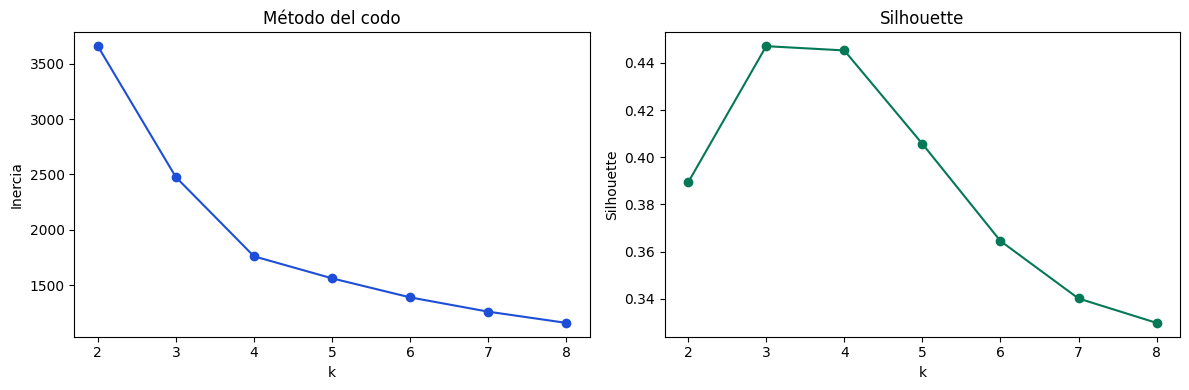

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertias, 'o-', color='#1d4ed8'); axes[0].set(title='Método del codo', xlabel='k', ylabel='Inercia')
axes[1].plot(ks, sils, 'o-', color='#047857'); axes[1].set(title='Silhouette', xlabel='k', ylabel='Silhouette')
plt.tight_layout(); plt.show()

**Decisión:** el codo está en **k = 4**: hasta 4 grupos la inercia baja ~30 % por cada grupo nuevo, y desde ahí apenas ~11 %. La silhouette de k = 3 y k = 4 está prácticamente empatada (≈0,447 vs ≈0,445), así que se elige k = 4, que además separa a los compradores de primera vivienda de los inversionistas (útil para el negocio). La regla está automatizada en `ml/train.py → choose_k`.

In [7]:
from ml.train import choose_k
best_k = choose_k(ks, inertias, sils)
print('k elegido:', best_k)

k elegido: 4


## 4. Entrenamiento y perfil de cada grupo

In [8]:
from ml.train import name_clusters
model = Pipeline([('prep', prep), ('kmeans', KMeans(n_clusters=best_k, n_init=10, random_state=42))])
labels = model.fit_predict(X)
centroides = [{f: df.loc[labels == c, f].mean() for f in SEGMENT_FEATURES} for c in range(best_k)]
nombres = name_clusters(centroides)
perfil = pd.DataFrame(centroides).assign(segmento=[nombres[c] for c in range(best_k)], clientes=[int((labels == c).sum()) for c in range(best_k)]).set_index('segmento')
perfil

,visitas,consultas,reservas,monto_reservado_usd,presupuesto_usd,dias_inactivo,interes_alquiler,clientes
segmento,,,,,,,,
Curioso,0.66,2.57,0.00,0.00,"92,405.80",124.15,0.40,224
Primera vivienda,3.02,4.03,1.04,"4,167.42","97,860.14",24.82,0.15,291
Inquilino,2.91,1.98,0.32,206.57,708.43,27.65,0.88,230
Inversionista,7.86,2.75,3.03,"21,017.16","330,936.71",9.43,0.10,155


Los nombres se asignan leyendo cada centroide: el grupo con más interés en alquiler es **Inquilino**, el más inactivo es **Curioso**, el de mayor presupuesto es **Inversionista** y el restante es **Primera vivienda**.

## 5. Visualización en 2D (PCA)

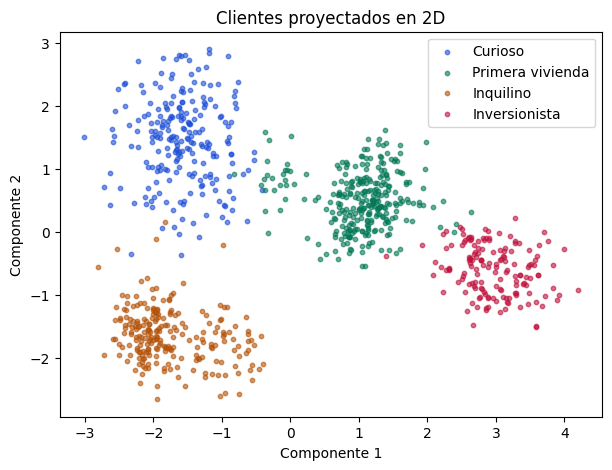

In [9]:
from sklearn.decomposition import PCA
pts = PCA(n_components=2, random_state=42).fit_transform(prep.transform(X))
fig, ax = plt.subplots(figsize=(7, 5))
colores = ['#1d4ed8', '#047857', '#b45309', '#be123c', '#7c3aed']
for c in range(best_k):
    m = labels == c
    ax.scatter(pts[m, 0], pts[m, 1], s=10, alpha=0.6, color=colores[c % 5], label=nombres[c])
ax.set(title='Clientes proyectados en 2D', xlabel='Componente 1', ylabel='Componente 2'); ax.legend(); plt.show()

## 6. ¿Encontró los perfiles reales? (solo evaluación)

In [10]:
from sklearn.metrics import adjusted_rand_score
print('ARI (1 = coincidencia perfecta, 0 = al azar):', round(adjusted_rand_score(df['perfil_real'], labels), 3))
pd.crosstab(df['perfil_real'], pd.Series([nombres[l] for l in labels], name='segmento K-means'))

ARI (1 = coincidencia perfecta, 0 = al azar): 0.928


segmento K-means,Curioso,Inquilino,Inversionista,Primera vivienda
perfil_real,,,,
Curioso,217,5,0,3
Inquilino,0,225,0,0
Inversionista,0,0,154,8
Primera vivienda,7,0,1,280


## Conclusión

- K-means encontró **4 segmentos** sin conocer las etiquetas, con una coincidencia **ARI ≈ 0,93** con los perfiles reales.
- El gateway calcula estas 7 variables para cada cliente real del sistema (visitas, consultas, reservas, contratos) y `ms-ml-python` los clasifica en `POST /api/v1/ml/segment-clients`; el Administrador lo ve en la pestaña **Segmentos**.
- **Límite honesto:** hoy hay pocos clientes reales; con más actividad conviene reentrenar el modelo con datos reales en lugar de sintéticos.